# tempnets: an example

This notebook walks through the package on a synthetic model and on the hospital contact data:
build a temporal network, form its temporal clique complex, compute zigzag persistence, and
summarise it with the autocorrelation and burstiness statistics. See the README for the
definitions and the paper for background on zigzag persistence.

Run it after installing the package from the repository root (`pip install -e .`).

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import tempnets as tn
from tempnets.topfunctions import pers_burstiness, top_burstiness

## 1. A random model, specified by density and rate

Every model takes the number of nodes `n`, the length `T` of the time interval, the average
**density** (fraction of node pairs joined at a time) and the average **rate** of new edges
(new edges per node pair per unit time). Edges then last `density / rate` time units on
average. `seed` makes the network reproducible.

In [2]:
net = tn.generators.er_periodic(n=25, T=60, density=0.3, rate=0.1, seed=1)
print(net)
net.stats()

TemporalNetwork(n=25, T=60, edges=188)


NetworkStats(density=0.3130560812814376, rate=0.1068888888888889)

A `TemporalNetwork` stores each edge's presence intervals; `level_set(t)` is the graph at time `t`.

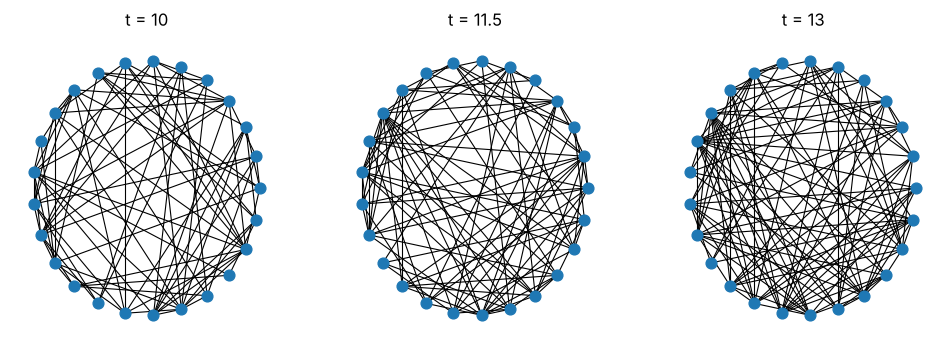

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
pos = nx.circular_layout(net.graph())
for ax, t in zip(axes, [10, 11.5, 13]):
    nx.draw(net.level_set(t), pos, ax=ax, node_size=60, width=0.8)
    ax.set_title("t = %g" % t)
plt.show()

## 2. Temporal clique complex and zigzag persistence

`flag(max_dim)` adds every clique of up to `max_dim + 1` nodes, present while all of its edges
are. `persistence()` returns one array of (birth, death) rows per homological dimension.

In [4]:
cx = net.flag(max_dim=2)
print(cx)
dgms = cx.persistence()
[d.shape for d in dgms]

TemporalComplex(T=60, simplices by dimension=[25, 188, 564])


[(28, 2), (1116, 2), (1691, 2)]

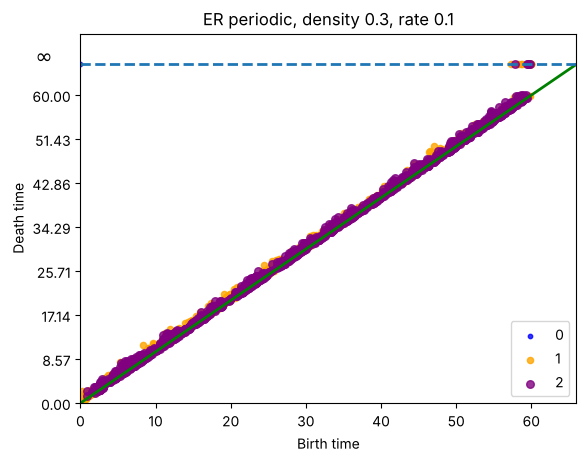

In [5]:
tn.plot_diags(dgms, net.T, title="ER periodic, density 0.3, rate 0.1")

## 3. Statistics

The autocorrelation statistics compare what is alive at times `t` and `t + tau` for every `t`
(no sampling grid), then take the autocorrelation of that similarity at lag `tau`. Here `tau` is
the spacing of 50 evenly spaced snapshots.

In [6]:
tau = net.T / 49
print("topological autocorrelation: %.3f" % tn.top_autocorr_continuous(dgms, tau, net.T))
print("graph autocorrelation:       %.3f" % net.graph_autocorrelation_continuous(tau))
print("burstiness of persistences:  %.3f" % pers_burstiness(dgms, net.T))

topological autocorrelation: -0.191
graph autocorrelation:       0.038
burstiness of persistences:  -0.074


## 4. Comparing the models at the same density and rate

`poisson` takes no rate: its contacts last one time step, so its rate follows from the density.

In [7]:
rows = []
for name in ["binomial", "poisson", "er_periodic", "ws_rewiring", "topological_rewiring"]:
    make = getattr(tn.generators, name)
    m = make(20, 60, 0.3, seed=2) if name == "poisson" else make(20, 60, 0.3, 0.1, seed=2)
    d = m.flag().persistence()
    density, rate = m.stats()
    rows.append(dict(model=name, density=density, rate=rate,
                     top_autocorr=tn.top_autocorr_continuous(d, m.T / 49, m.T),
                     graph_autocorr=m.graph_autocorrelation_continuous(m.T / 49)))
pd.DataFrame(rows).round(3)

,model,density,rate,top_autocorr,graph_autocorr
0,binomial,0.308,0.100,0.150,-0.079
1,poisson,0.296,0.254,0.519,-0.114
2,er_periodic,0.322,0.110,0.025,-0.063
3,ws_rewiring,0.316,0.098,0.041,-0.259
4,topological_rewiring,0.268,0.098,0.044,0.191


## 5. Hospital contact data

Contacts between patients and staff in a hospital ward, recorded every 20 seconds over about
four days (SocioPatterns; Vanhems et al., 2013). Each contact keeps its edge present for its
own 20-second step plus a **buffer**. A triangle is present only when all three of its pairs are
in contact at the same recorded time, and is then kept for the same duration
(`TemporalComplex.from_contacts`). Time is in hours.

TemporalNetwork(n=75, T=96.5722, edges=1139)
TemporalComplex(T=96.5722, simplices by dimension=[75, 1139, 703])


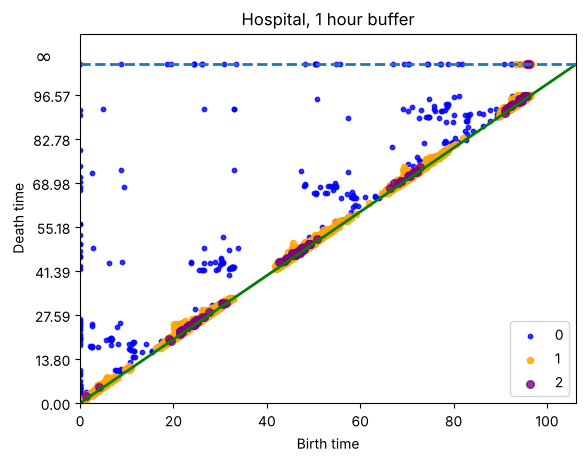

In [8]:
hosp = pd.read_csv("../data/detailed_list_of_contacts_Hospital.dat", sep="\t", header=None,
                   names=["t", "i", "j", "type1", "type2"])
contacts = [(i, j, t / 3600) for (i, j, t) in hosp[["i", "j", "t"]].values.tolist()]
step = 20 / 3600
T = hosp["t"].max() / 3600 + step
duration = step + 1  # a one-hour buffer

hnet = tn.TemporalNetwork.from_contacts(contacts, duration, T=T)
hcx = tn.TemporalComplex.from_contacts(contacts, duration, max_dim=2, T=T)
print(hnet)
print(hcx)
hdgms = hcx.persistence()
tn.plot_diags(hdgms, T, title="Hospital, 1 hour buffer")

In [9]:
tau = T / 49
print("topological autocorrelation: %.3f" % tn.top_autocorr_continuous(hdgms, tau, T))
print("graph autocorrelation:       %.3f" % hnet.graph_autocorrelation_continuous(tau))
print("burstiness of birth/death times by dimension:", np.round(top_burstiness(hdgms, T), 3))

topological autocorrelation: 0.811


graph autocorrelation:       0.621
burstiness of birth/death times by dimension: [0.478 0.435 0.752 0.752 0.57  0.564]


`tests/hospital.py` repeats this for buffers from one minute to 48 hours, and
`python -m tempnets.models` runs the comparison experiments on the random models.